# Machine Learning - Lab Assignment
## Linear Regression, Ridge and Lasso

Name: aicha chibani    Group: 2    Date: 05/11/2026

Use Python 3 and Jupyter Notebook. Required packages: `numpy`, `pandas`, `matplotlib`, and `scikit-learn`. If needed, install them with `pip install numpy pandas matplotlib scikit-learn`.

Work through the tasks in order. Create the dataset in Task 1; no external file is needed.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

### Task 1. Generate the dataset

Create a DataFrame named `df` with 500 synthetic salary records:

- Set the NumPy random seed to **42**.
- Generate 500 integers for `YearsOfExperience`, between **2 and 20 inclusive**, with `np.random.randint(2, 21, size=500)`.
- Set `intercept = 60000` and `slope = (200000 - 60000) / (20 - 2)`.
- Generate 500 noise values from a normal distribution using `np.random.normal(0, 10000, size=500)`.
- Compute `Salary = intercept + slope * YearsOfExperience + noise`.
- Use pandas to create `df` with exactly two columns: `YearsOfExperience` and `Salary`. Display its first five rows and check that its shape is `(500, 2)`.

Generate the experience values **before** generating the noise. Do not load a dataset from a file.

In [2]:
np.random.seed(42)

# Experience first, then noise (order matters for reproducibility)
years = np.random.randint(2, 21, size=500)

intercept = 60000
slope = (200000 - 60000) / (20 - 2)

noise = np.random.normal(0, 10000, size=500)
salary = intercept + slope * years + noise

df = pd.DataFrame({"YearsOfExperience": years, "Salary": salary})

display(df.head())
print("Shape:", df.shape)
assert df.shape == (500, 2)

,YearsOfExperience,Salary
0,8,115037.780010
1,16,182309.972927
2,12,156442.408989
3,9,144753.562169
4,8,130798.818454


Shape: (500, 2)


### Task 2. Explore the dataset

Display the dataset shape, summary statistics and number of missing values in each column. Calculate the correlation between `YearsOfExperience` and `Salary`.

In [3]:
print("Shape:", df.shape)

print("\nSummary statistics:")
display(df.describe())

print("\nMissing values per column:")
print(df.isnull().sum())

corr = df["YearsOfExperience"].corr(df["Salary"])
print(f"\nCorrelation between YearsOfExperience and Salary: {corr:.4f}")

Shape: (500, 2)

Summary statistics:


,YearsOfExperience,Salary
count,500.000000,500.000000
mean,10.616000,142570.011096
std,5.662922,44935.263058
min,2.000000,54881.134555
25%,5.750000,104426.300731
50%,10.000000,139865.032545
75%,16.000000,182341.125962
max,20.000000,241879.376204



Missing values per column:
YearsOfExperience    0
Salary               0
dtype: int64

Correlation between YearsOfExperience and Salary: 0.9751


### Task 3. Plot the data

Draw a scatter plot with `YearsOfExperience` on the x-axis and `Salary` on the y-axis. Add axis labels and a title.

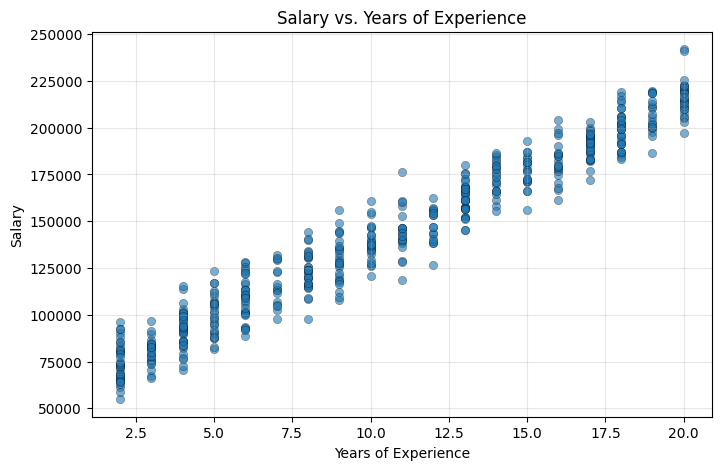

In [4]:
plt.figure(figsize=(8, 5))
plt.scatter(df["YearsOfExperience"], df["Salary"], alpha=0.6, edgecolor="k", linewidth=0.3)
plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.title("Salary vs. Years of Experience")
plt.grid(alpha=0.3)
plt.show()

### Task 4. Split the dataset

Set `X` to the `YearsOfExperience` column as a two-dimensional DataFrame and `y` to `Salary`. Use `train_test_split` with `test_size=0.20` and `random_state=42`. Display the number of training and test records.

In [5]:
X = df[["YearsOfExperience"]]   # double brackets -> 2D DataFrame
y = df["Salary"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training records:", len(X_train))
print("Test records:    ", len(X_test))

Training records: 400
Test records:     100


### Task 5. Train linear regression

Fit a `LinearRegression` model on the training data. Display the slope, intercept, training R2 and test R2.

In [6]:
lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)

print(f"Slope:     {lin_reg.coef_[0]:.2f}")
print(f"Intercept: {lin_reg.intercept_:.2f}")
print(f"Training R2: {lin_reg.score(X_train, y_train):.4f}")
print(f"Test R2:     {lin_reg.score(X_test, y_test):.4f}")

Slope:     7696.61
Intercept: 60961.34
Training R2: 0.9488
Test R2:     0.9574


### Task 6. Evaluate linear regression

Predict salary for the test set. Calculate MAE, MSE, RMSE and R2. Display the first five actual and predicted salaries in a table.

In [7]:
y_pred = lin_reg.predict(X_test)

lin_mae = mean_absolute_error(y_test, y_pred)
lin_mse = mean_squared_error(y_test, y_pred)
lin_rmse = np.sqrt(lin_mse)
lin_r2 = r2_score(y_test, y_pred)

print(f"MAE:  {lin_mae:.2f}")
print(f"MSE:  {lin_mse:.2f}")
print(f"RMSE: {lin_rmse:.2f}")
print(f"R2:   {lin_r2:.4f}")

comparison = pd.DataFrame({
    "Actual Salary": y_test.values[:5],
    "Predicted Salary": y_pred[:5],
}).round(2)
display(comparison)

MAE:  7905.11
MSE:  93933277.38
RMSE: 9691.92
R2:   0.9574


,Actual Salary,Predicted Salary
0,123631.23,107141.02
1,139775.63,122534.24
2,93184.81,107141.02
3,166740.80,161017.31
4,174587.18,184107.15


### Task 7. Compare with a baseline

Use the mean of `y_train` as the predicted salary for every test record. Compute baseline MAE and RMSE and compare them with linear regression.

In [8]:
baseline_pred = np.full(len(y_test), y_train.mean())

base_mae = mean_absolute_error(y_test, baseline_pred)
base_rmse = np.sqrt(mean_squared_error(y_test, baseline_pred))
base_r2 = r2_score(y_test, baseline_pred)

print(f"Baseline prediction (mean of y_train): {y_train.mean():.2f}")
print(f"Baseline MAE:  {base_mae:.2f}")
print(f"Baseline RMSE: {base_rmse:.2f}")
print()
print(f"Linear regression MAE:  {lin_mae:.2f}")
print(f"Linear regression RMSE: {lin_rmse:.2f}")
print()
print(f"MAE reduced by  {100 * (1 - lin_mae / base_mae):.1f}% compared with the baseline")
print(f"RMSE reduced by {100 * (1 - lin_rmse / base_rmse):.1f}% compared with the baseline")

Baseline prediction (mean of y_train): 142353.02
Baseline MAE:  40444.96
Baseline RMSE: 46953.77

Linear regression MAE:  7905.11
Linear regression RMSE: 9691.92

MAE reduced by  80.5% compared with the baseline
RMSE reduced by 79.4% compared with the baseline


### Task 8. Plot predictions and residuals

Make two graphs: (a) test observations and the fitted regression line; (b) residuals (`actual - predicted`) against years of experience, with a horizontal line at zero.

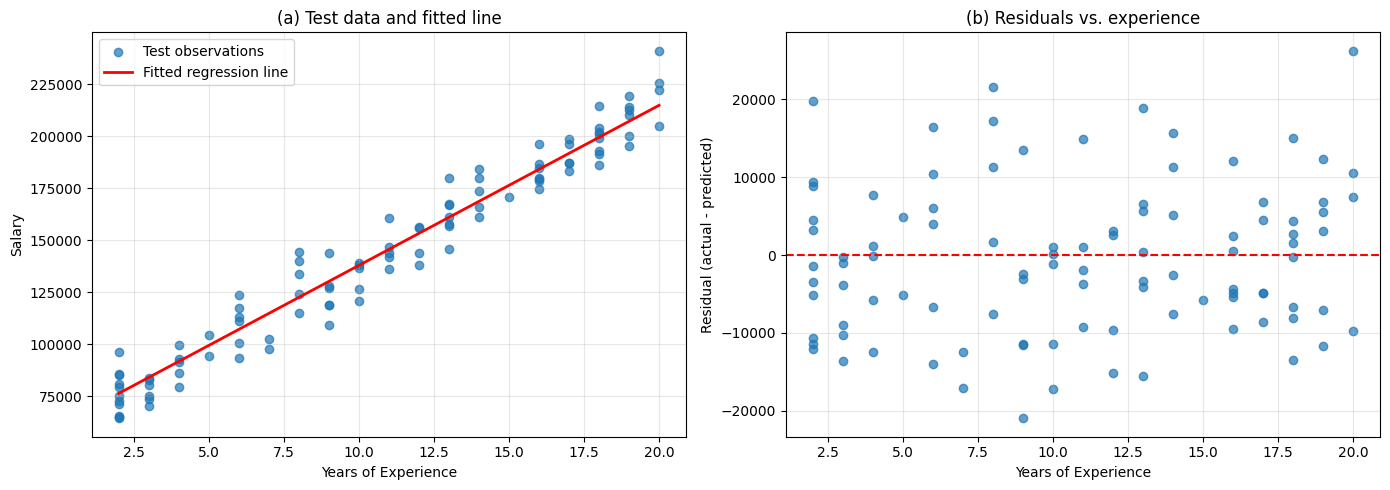

In [9]:
residuals = y_test - y_pred

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# (a) test observations + fitted line
axes[0].scatter(X_test["YearsOfExperience"], y_test, alpha=0.7, label="Test observations")
x_line = pd.DataFrame({"YearsOfExperience": np.linspace(2, 20, 100)})
axes[0].plot(x_line["YearsOfExperience"], lin_reg.predict(x_line),
             color="red", linewidth=2, label="Fitted regression line")
axes[0].set_xlabel("Years of Experience")
axes[0].set_ylabel("Salary")
axes[0].set_title("(a) Test data and fitted line")
axes[0].legend()
axes[0].grid(alpha=0.3)

# (b) residuals
axes[1].scatter(X_test["YearsOfExperience"], residuals, alpha=0.7)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_xlabel("Years of Experience")
axes[1].set_ylabel("Residual (actual - predicted)")
axes[1].set_title("(b) Residuals vs. experience")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Task 9. Predict new salaries

Use the linear regression model to predict salaries for **5, 10 and 15 years** of experience. Display the results in a table.

In [10]:
new_data = pd.DataFrame({"YearsOfExperience": [5, 10, 15]})
new_pred = lin_reg.predict(new_data)

predictions_table = pd.DataFrame({
    "YearsOfExperience": new_data["YearsOfExperience"],
    "Predicted Salary": new_pred.round(2),
})
display(predictions_table)

,YearsOfExperience,Predicted Salary
0,5,99444.41
1,10,137927.47
2,15,176410.53


### Task 10. Standardize the feature

Use `StandardScaler` on `X_train` and `X_test`. Fit the scaler on the training set only, then transform both sets. Keep the target `y` unchanged.

In [11]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # fit on training data only
X_test_scaled = scaler.transform(X_test)         # reuse training mean/std

print(f"Training mean used by scaler: {scaler.mean_[0]:.4f}")
print(f"Training std used by scaler:  {scaler.scale_[0]:.4f}")
print(f"Scaled X_train -> mean {X_train_scaled.mean():.4f}, std {X_train_scaled.std():.4f}")
print(f"Scaled X_test  -> mean {X_test_scaled.mean():.4f}, std {X_test_scaled.std():.4f}")

Training mean used by scaler: 10.5750
Training std used by scaler:  5.6142
Scaled X_train -> mean 0.0000, std 1.0000
Scaled X_test  -> mean 0.0365, std 1.0373


### Task 11. Train Ridge regression

Fit two `Ridge` models on the scaled training set, using `alpha=10` and `alpha=100`. For each model, display its coefficient, test MAE and test R2. Compare the coefficients. Keep the `alpha=10` model for Task 13.

In [12]:
ridge_models = {}
for alpha in [10, 100]:
    model = Ridge(alpha=alpha)
    model.fit(X_train_scaled, y_train)
    pred = model.predict(X_test_scaled)
    ridge_models[alpha] = model
    print(f"Ridge alpha={alpha}")
    print(f"  Coefficient: {model.coef_[0]:.2f}")
    print(f"  Test MAE:    {mean_absolute_error(y_test, pred):.2f}")
    print(f"  Test R2:     {r2_score(y_test, pred):.4f}")
    print()

ridge_10 = ridge_models[10]   # kept for Task 13

print("Coefficient comparison:",
      f"alpha=10 -> {ridge_models[10].coef_[0]:.2f},",
      f"alpha=100 -> {ridge_models[100].coef_[0]:.2f}")

Ridge alpha=10
  Coefficient: 42156.50
  Test MAE:    8084.46
  Test R2:     0.9557

Ridge alpha=100
  Coefficient: 34568.33
  Test MAE:    11308.37
  Test R2:     0.9118

Coefficient comparison: alpha=10 -> 42156.50, alpha=100 -> 34568.33


### Task 12. Train Lasso regression

Fit three `Lasso` models on the scaled training set, using `alpha=1000`, `alpha=10000` and `alpha=50000`. Set `max_iter=20000`. For each model, display its coefficient, test MAE and test R2. Observe what happens to the coefficient as alpha increases. Keep the `alpha=1000` model for Task 13.

In [13]:
lasso_models = {}
for alpha in [1000, 10000, 50000]:
    model = Lasso(alpha=alpha, max_iter=20000)
    model.fit(X_train_scaled, y_train)
    pred = model.predict(X_test_scaled)
    lasso_models[alpha] = model
    print(f"Lasso alpha={alpha}")
    print(f"  Coefficient: {model.coef_[0]:.2f}")
    print(f"  Test MAE:    {mean_absolute_error(y_test, pred):.2f}")
    print(f"  Test R2:     {r2_score(y_test, pred):.4f}")
    print()

lasso_1000 = lasso_models[1000]   # kept for Task 13

print("Coefficient vs. alpha:",
      ", ".join(f"alpha={a} -> {m.coef_[0]:.2f}" for a, m in lasso_models.items()))

Lasso alpha=1000
  Coefficient: 42210.42
  Test MAE:    8074.65
  Test R2:     0.9558

Lasso alpha=10000
  Coefficient: 33210.42
  Test MAE:    12287.96
  Test R2:     0.8980

Lasso alpha=50000
  Coefficient: 0.00
  Test MAE:    40444.96
  Test R2:     -0.0005

Coefficient vs. alpha: alpha=1000 -> 42210.42, alpha=10000 -> 33210.42, alpha=50000 -> 0.00


### Task 13. Compare the models

Create a table showing test MAE, RMSE and R2 for: the mean baseline, linear regression, Ridge (`alpha=10`) and Lasso (`alpha=1000`). Write two sentences about the results.

In [14]:
def evaluate(y_true, y_hat):
    return {
        "Test MAE": mean_absolute_error(y_true, y_hat),
        "Test RMSE": np.sqrt(mean_squared_error(y_true, y_hat)),
        "Test R2": r2_score(y_true, y_hat),
    }

results = pd.DataFrame({
    "Mean baseline": evaluate(y_test, baseline_pred),
    "Linear regression": evaluate(y_test, lin_reg.predict(X_test)),
    "Ridge (alpha=10)": evaluate(y_test, ridge_10.predict(X_test_scaled)),
    "Lasso (alpha=1000)": evaluate(y_test, lasso_1000.predict(X_test_scaled)),
}).T.round(4)

display(results)

,Test MAE,Test RMSE,Test R2
Mean baseline,40444.9579,46953.7695,-0.0005
Linear regression,7905.1147,9691.9181,0.9574
Ridge (alpha=10),8084.4613,9876.9316,0.9557
Lasso (alpha=1000),8074.6515,9864.6082,0.9558


**Comparison (Task 13):** All three models are far better than the mean baseline (test MAE about 8,000 versus about 40,400, and R2 about 0.96 versus 0), which confirms that years of experience strongly predicts salary. Plain linear regression is slightly the best (MAE 7,905, R2 0.9574), while Ridge (alpha=10) and Lasso (alpha=1000) are almost identical to it because there is only one feature and little overfitting, so regularization shrinks the coefficient a little and does not help here (and a very large alpha, such as Lasso with alpha=50000, shrinks the coefficient to 0 and collapses to the baseline).

**Submission:** Save the notebook with your code, results and plots. Include your short comparison for Task 13.